#**Import Libraries**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import OrdinalEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

#**Reading The File**

In [2]:
df_stu = pd.read_csv("/content/drive/MyDrive/ICT_AIML_DATAS/DataFrame/Student_Depression_Dataset.csv")

In [3]:
df_stu.head()

,Gender,Age,Family_background,Relationship_status,Marital_status,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression
0,Female,22,Middle class,Single,Unmarried,Bachelor,8,3.43,Yes,Critical,10113,Chittagong,Yes
1,Male,19,Middle class,Single,Unmarried,Bachelor,2,3.70,Yes,Abnormal,13815,Chittagong,Yes
2,Male,23,Middle class,Single,Unmarried,Family,8,3.28,No,Abnormal,15450,Dhaka,Yes
3,Male,20,Middle class,Complicated,Unmarried,Family,2,3.77,No,Good,17413,Dhaka,No
4,Female,21,Middle class,Single,Unmarried,Family,1,4.00,No,Abnormal,16693,Dhaka,Yes


In [4]:
df_stu.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4464 entries, 0 to 4463
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Gender               4464 non-null   object 
 1   Age                  4464 non-null   int64  
 2   Family_background    4464 non-null   object 
 3   Relationship_status  4464 non-null   object 
 4   Marital_status       4464 non-null   object 
 5   Living_style         4464 non-null   object 
 6   Current_semester     4464 non-null   int64  
 7   CGPA                 4464 non-null   float64
 8   friend_circle        4464 non-null   object 
 9   Health_condition     4464 non-null   object 
 10  Cost_without_study   4464 non-null   int64  
 11  Home_division        4464 non-null   object 
 12  Depression           4464 non-null   object 
dtypes: float64(1), int64(3), object(9)
memory usage: 453.5+ KB


In [5]:
df_stu.describe()

,Age,Current_semester,CGPA,Cost_without_study
count,4464.000000,4464.000000,4464.000000,4464.000000
mean,22.619176,5.401210,3.412753,11242.978271
std,2.022980,2.578476,0.385605,6640.144019
min,17.000000,0.000000,2.250000,0.000000
25%,21.000000,3.000000,3.150000,6100.000000
50%,23.000000,5.000000,3.490000,9500.000000
75%,24.000000,7.000000,3.700000,15439.000000
max,28.000000,13.000000,4.000000,32000.000000


In [6]:
df_stu.columns

Index(['Gender', 'Age', 'Family_background', 'Relationship_status',
       'Marital_status', 'Living_style', 'Current_semester', 'CGPA',
       'friend_circle', 'Health_condition', 'Cost_without_study',
       'Home_division', 'Depression'],
      dtype='object')

In [7]:
df_stu.shape

(4464, 13)

In [8]:
df_stu.isna().sum()

,0
Gender,0
Age,0
Family_background,0
Relationship_status,0
Marital_status,0
Living_style,0
Current_semester,0
CGPA,0
friend_circle,0
Health_condition,0


In [9]:
df_stu.duplicated().sum() #No duplicated rows

np.int64(0)

In [10]:
cat_cols = df_stu.select_dtypes(include = "object")
num_cols = df_stu.select_dtypes(include = "number" )


In [11]:
cat_cols.head()

,Gender,Family_background,Relationship_status,Marital_status,Living_style,friend_circle,Health_condition,Home_division,Depression
0,Female,Middle class,Single,Unmarried,Bachelor,Yes,Critical,Chittagong,Yes
1,Male,Middle class,Single,Unmarried,Bachelor,Yes,Abnormal,Chittagong,Yes
2,Male,Middle class,Single,Unmarried,Family,No,Abnormal,Dhaka,Yes
3,Male,Middle class,Complicated,Unmarried,Family,No,Good,Dhaka,No
4,Female,Middle class,Single,Unmarried,Family,No,Abnormal,Dhaka,Yes


In [12]:
cat_cols.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4464 entries, 0 to 4463
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   Gender               4464 non-null   object
 1   Family_background    4464 non-null   object
 2   Relationship_status  4464 non-null   object
 3   Marital_status       4464 non-null   object
 4   Living_style         4464 non-null   object
 5   friend_circle        4464 non-null   object
 6   Health_condition     4464 non-null   object
 7   Home_division        4464 non-null   object
 8   Depression           4464 non-null   object
dtypes: object(9)
memory usage: 314.0+ KB


In [13]:
num_cols.head()

,Age,Current_semester,CGPA,Cost_without_study
0,22,8,3.43,10113
1,19,2,3.70,13815
2,23,8,3.28,15450
3,20,2,3.77,17413
4,21,1,4.00,16693


In [14]:
num_cols.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4464 entries, 0 to 4463
Data columns (total 4 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Age                 4464 non-null   int64  
 1   Current_semester    4464 non-null   int64  
 2   CGPA                4464 non-null   float64
 3   Cost_without_study  4464 non-null   int64  
dtypes: float64(1), int64(3)
memory usage: 139.6 KB


In [15]:
num_cols.duplicated().sum() #It makes error only look at for whole dataframe

np.int64(109)

In [16]:
df_stu.duplicated().sum() #No duplicated rows

np.int64(0)

In [17]:
cat_cols.isnull().sum() #No null or missing values

,0
Gender,0
Family_background,0
Relationship_status,0
Marital_status,0
Living_style,0
friend_circle,0
Health_condition,0
Home_division,0
Depression,0


In [18]:
num_cols.isnull().sum() #No null or missing values

,0
Age,0
Current_semester,0
CGPA,0
Cost_without_study,0


#**OUTLIER HANDLING**

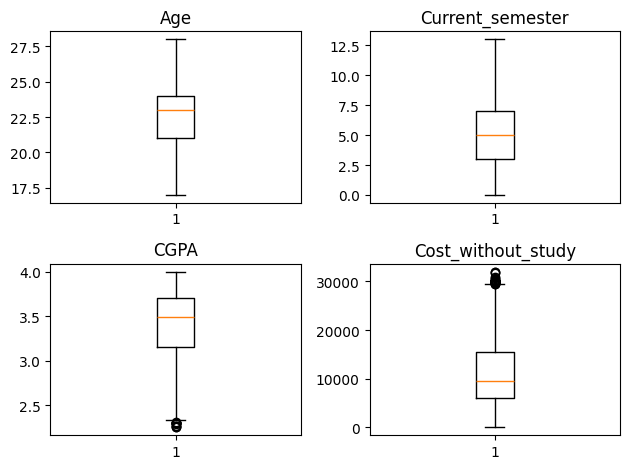

In [19]:
for i, col in enumerate(num_cols.columns,1):
  plt.subplot(2,2 ,i)
  plt.boxplot(df_stu[col])
  plt.title(col)
plt.tight_layout()
plt.show()

In [20]:
cols = ["CGPA","Cost_without_study"]
for col in cols:
  Q1 = df_stu[col].quantile(0.25)
  Q3 = df_stu[col].quantile(0.75)

  IQR = Q3 - Q1
  lower = Q1 - 1.5*IQR
  upper = Q3 + 1.5*IQR

  df_stu[col] = df_stu[col].clip(lower,upper)

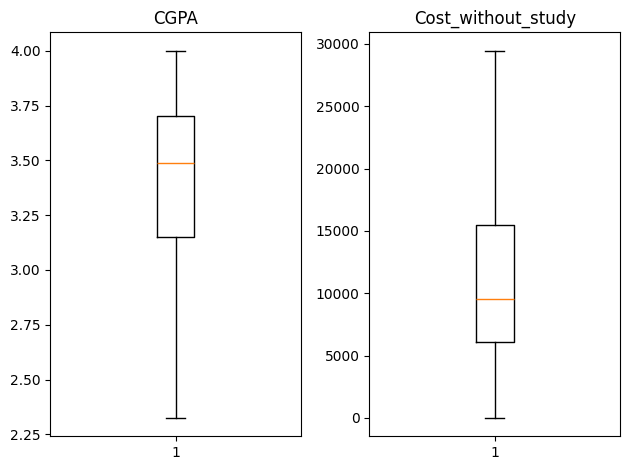

In [21]:
for i, col in enumerate(cols, 1):
    plt.subplot(1, 2, i)
    plt.boxplot(df_stu[col])
    plt.title(col)

plt.tight_layout()
plt.show()

#**Label Encoding**

Depression

In [22]:
label_encoder = LabelEncoder()
df_stu["Depression"] = label_encoder.fit_transform(df_stu["Depression"])

In [23]:
print(df_stu["Depression"].head())
print(df_stu["Depression"].unique())

0    1
1    1
2    1
3    0
4    1
Name: Depression, dtype: int64
[1 0]


In [24]:
df_stu.head() #Depression comes to number because it is encoded

,Gender,Age,Family_background,Relationship_status,Marital_status,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression
0,Female,22,Middle class,Single,Unmarried,Bachelor,8,3.43,Yes,Critical,10113.0,Chittagong,1
1,Male,19,Middle class,Single,Unmarried,Bachelor,2,3.70,Yes,Abnormal,13815.0,Chittagong,1
2,Male,23,Middle class,Single,Unmarried,Family,8,3.28,No,Abnormal,15450.0,Dhaka,1
3,Male,20,Middle class,Complicated,Unmarried,Family,2,3.77,No,Good,17413.0,Dhaka,0
4,Female,21,Middle class,Single,Unmarried,Family,1,4.00,No,Abnormal,16693.0,Dhaka,1


#**ORDINAL ENCODING**

In [25]:
df_stu["Health_condition"].unique()

array(['Critical', 'Abnormal', 'Good', 'Normal'], dtype=object)

Health Condition

ORDER : Normal > Good > Abnormal > Critical


In [26]:
encoder_health = OrdinalEncoder()
encoder_health = OrdinalEncoder(
    categories = [["Normal","Good","Abnormal","Critical"]]
)
df_stu["Health_condition"] = encoder_health.fit_transform(df_stu[["Health_condition"]])

In [27]:
df_stu["Health_condition"].head()

,Health_condition
0,3.0
1,2.0
2,2.0
3,1.0
4,2.0


In [28]:
print(df_stu["Health_condition"].unique())
print(df_stu["Health_condition"].head(10))

[3. 2. 1. 0.]
0    3.0
1    2.0
2    2.0
3    1.0
4    2.0
5    0.0
6    0.0
7    2.0
8    2.0
9    0.0
Name: Health_condition, dtype: float64


FAMILY BACKGROUND

In [29]:
df_stu["Family_background"].unique()

array(['Middle class', 'Lower Middle class', 'Rich class'], dtype=object)

In [30]:
encoder_family = OrdinalEncoder(
    categories=[["Lower Middle class", "Middle class", "Rich class"]]
)
df_stu["Family_background"] = encoder_family.fit_transform(df_stu[["Family_background"]])

In [31]:
print(df_stu["Family_background"].unique())
print(df_stu["Family_background"].head(10))

[1. 0. 2.]
0    1.0
1    1.0
2    1.0
3    1.0
4    1.0
5    1.0
6    0.0
7    1.0
8    1.0
9    1.0
Name: Family_background, dtype: float64


#**ONE HOT ENCODING**

Gender

In [32]:
o_encoder_gender = OneHotEncoder()
o_encoded_data_gender = o_encoder_gender.fit_transform(df_stu[["Gender"]])
o_encoded_df_gender = pd.DataFrame(
    o_encoded_data_gender.toarray(),
    columns = o_encoder_gender.get_feature_names_out(["Gender"]),
    index = df_stu.index
)
df_stu = pd.concat([df_stu.drop("Gender",axis=1),o_encoded_df_gender],axis=1)

Relationship Status

In [33]:
o_encoder_rs = OneHotEncoder()
o_encoded_data_rs = o_encoder_rs.fit_transform(df_stu[["Relationship_status"]])
o_encoded_df_rs = pd.DataFrame(
    o_encoded_data_rs.toarray(),
    columns = o_encoder_rs.get_feature_names_out(["Relationship_status"]),
    index = df_stu.index
)
df_stu = pd.concat([df_stu.drop("Relationship_status",axis=1),o_encoded_df_rs],axis=1)

Living Style

In [34]:
o_encoder_liv = OneHotEncoder()
o_encoded_data_liv = o_encoder_liv.fit_transform(df_stu[["Living_style"]])
o_encoded_df_liv = pd.DataFrame(
    o_encoded_data_liv.toarray(),
    columns = o_encoder_liv.get_feature_names_out(["Living_style"]),
    index = df_stu.index
)
df_stu = pd.concat([df_stu.drop("Living_style",axis=1),o_encoded_df_rs],axis=1)

Friend Circle

In [35]:
o_encoder_fri = OneHotEncoder()
o_encoded_data_fri = o_encoder_fri.fit_transform(df_stu[["friend_circle"]])
o_encoded_df_fri = pd.DataFrame(
    o_encoded_data_fri.toarray(),
    columns = o_encoder_fri.get_feature_names_out(["friend_circle"]),
    index = df_stu.index
)
df_stu = pd.concat([df_stu.drop("friend_circle",axis=1),o_encoded_df_fri],axis=1)

Martital Status

In [36]:
o_encoder_mar = OneHotEncoder()
o_encoded_data_mar = o_encoder_mar.fit_transform(df_stu[["Marital_status"]])
o_encoded_df_mar = pd.DataFrame(
    o_encoded_data_mar.toarray(),
    columns = o_encoder_mar.get_feature_names_out(["Marital_status"]),
    index = df_stu.index
)
df_stu = pd.concat([df_stu.drop("Marital_status",axis=1),o_encoded_df_mar],axis=1)

Home Division

In [37]:
o_encoder_home = OneHotEncoder()
o_encoded_data_home = o_encoder_home.fit_transform(df_stu[["Home_division"]])
o_encoded_df_home = pd.DataFrame(
    o_encoded_data_home.toarray(),
    columns = o_encoder_home.get_feature_names_out(["Home_division"]),
    index = df_stu.index
)
df_stu = pd.concat([df_stu.drop("Home_division",axis=1),o_encoded_df_home],axis=1)

In [38]:
df_stu.head(10)

,Age,Family_background,Current_semester,CGPA,Health_condition,Cost_without_study,Depression,Gender_Female,Gender_Male,Relationship_status_Complicated,...,Marital_status_Separated,Marital_status_Unmarried,Home_division_Barisal,Home_division_Chittagong,Home_division_Dhaka,Home_division_Khulna,Home_division_Mymensingh,Home_division_Rajshahi,Home_division_Rangpur,Home_division_Sylhet
0,22,1.0,8,3.43,3.0,10113.0,1,1.0,0.0,0.0,...,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
1,19,1.0,2,3.70,2.0,13815.0,1,0.0,1.0,0.0,...,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
2,23,1.0,8,3.28,2.0,15450.0,1,0.0,1.0,0.0,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
3,20,1.0,2,3.77,1.0,17413.0,0,0.0,1.0,1.0,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
4,21,1.0,1,4.00,2.0,16693.0,1,1.0,0.0,0.0,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
5,24,1.0,9,3.80,0.0,17244.0,0,1.0,0.0,0.0,...,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
6,21,0.0,9,3.50,0.0,1648.0,0,1.0,0.0,0.0,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
7,19,1.0,2,2.71,2.0,16782.0,1,1.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
8,21,1.0,3,3.10,2.0,13386.0,1,1.0,0.0,0.0,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
9,22,1.0,4,3.34,0.0,18131.0,0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0


#**Standard scaler**

In [39]:
num_cols.head()

,Age,Current_semester,CGPA,Cost_without_study
0,22,8,3.43,10113
1,19,2,3.70,13815
2,23,8,3.28,15450
3,20,2,3.77,17413
4,21,1,4.00,16693


In [40]:
scaler = StandardScaler()
scaled_data = scaler.fit_transform(num_cols)
df_stu[num_cols.columns] = scaled_data
print(df_stu.head())

        Age  Family_background  Current_semester      CGPA  Health_condition  \
0 -0.306105                1.0          1.007991  0.044732               3.0   
1 -1.789232                1.0         -1.319225  0.745009               2.0   
2  0.188270                1.0          1.007991 -0.344311               2.0   
3 -1.294857                1.0         -1.319225  0.926563               1.0   
4 -0.800481                1.0         -1.707095  1.523095               2.0   

   Cost_without_study  Depression  Gender_Female  Gender_Male  \
0           -0.170193           1            1.0          0.0   
1            0.387388           1            0.0          1.0   
2            0.633645           1            0.0          1.0   
3            0.929304           0            0.0          1.0   
4            0.820861           1            1.0          0.0   

   Relationship_status_Complicated  ...  Marital_status_Separated  \
0                              0.0  ...                    